# Семинар 6. Регуляризация и кросс-валидация

Сегодня исследуем, как Ridge и Lasso изменяют коэффициенты линейной регрессии, как оценивать модель с помощью кросс-валидации и как выбирать силу регуляризации. Основной пример — прогноз месячной арендной платы по характеристикам квартиры.

## 1. Данные об аренде квартир

Работаем с синтетическими объявлениями об аренде в условном городе. Целевая переменная — месячная плата в **тысячах рублей**. В таблице 160 квартир, а все признаки числовые: кодирование категорий пока не требуется.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, LogisticRegression
from sklearn.metrics import root_mean_squared_error, mean_squared_error, roc_auc_score
from sklearn.datasets import load_breast_cancer

plt.rcParams.update({"figure.figsize": (8, 4.5), "font.size": 11})

In [2]:
data = pd.read_csv("apartment_rent_data.csv")
print("Размер таблицы:", data.shape)
display(data.head())

Размер таблицы: (160, 13)


,total_area_m2,living_area_m2,kitchen_area_m2,rooms,distance_center_km,walk_to_metro_min,building_age_years,renovation_score_1to5,ceiling_height_m,floor,balconies,listing_day,monthly_rent_thousand_rub
0,47.930673,34.004103,6.645431,1,8.803677,14.198596,52,1,2.618265,11,1,1,46.551640
1,67.570854,51.001019,11.204539,2,4.417624,6.872553,41,1,2.500000,1,0,21,70.362358
2,30.000000,22.109687,5.679897,1,6.155645,11.025785,69,5,2.822609,19,1,14,39.386058
3,89.519662,60.355581,14.132309,4,9.651718,7.428919,1,3,2.846303,17,0,22,100.720458
4,75.127600,55.833354,12.103396,2,2.787882,10.716231,46,1,2.595833,9,1,15,60.275834


### Что означают признаки

| Столбец | Описание |
|---|---|
| `total_area_m2`, `living_area_m2`, `kitchen_area_m2` | Общая, жилая и кухонная площади, м² |
| `rooms` | Число комнат |
| `distance_center_km` | Расстояние до центра, км |
| `walk_to_metro_min` | Время пешком до метро, мин |
| `building_age_years` | Возраст здания, лет |
| `renovation_score_1to5` | Оценка качества ремонта от 1 до 5 |
| `ceiling_height_m`, `floor`, `balconies` | Высота потолков, этаж, количество балконов |
| `listing_day` | Номер дня публикации объявления |
| `monthly_rent_thousand_rub` | **Месячная аренда, тыс. ₽ (цель)** |

Общая и жилая площади тесно связаны между собой; позже это поможет увидеть нестабильность коэффициентов. `listing_day` включён для проверки: в генераторе дата публикации не влияет на цену. Оценку ремонта мы используем как числовую переменную и тем самым предполагаем равные изменения между соседними баллами.

### Сначала отделяем финальный test

Откладываем 40 квартир и больше не обращаемся к ним до завершения выбора моделей. Оставшиеся 120 объектов называем **dev** — данными для исследования, проверки гипотез, валидации и настройки.

In [3]:
X = data.drop(columns="monthly_rent_thousand_rub")
y = data["monthly_rent_thousand_rub"]

X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)
print("Dev:", X_dev.shape, "Test:", X_test.shape)

Dev: (120, 12) Test: (40, 12)


In [4]:
data_dev = X_dev.assign(monthly_rent_thousand_rub=y_dev)
data_dev.info()

<class 'pandas.core.frame.DataFrame'>
Index: 120 entries, 26 to 102
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   total_area_m2              120 non-null    float64
 1   living_area_m2             120 non-null    float64
 2   kitchen_area_m2            120 non-null    float64
 3   rooms                      120 non-null    int64  
 4   distance_center_km         120 non-null    float64
 5   walk_to_metro_min          120 non-null    float64
 6   building_age_years         120 non-null    int64  
 7   renovation_score_1to5      120 non-null    int64  
 8   ceiling_height_m           120 non-null    float64
 9   floor                      120 non-null    int64  
 10  balconies                  120 non-null    int64  
 11  listing_day                120 non-null    int64  
 12  monthly_rent_thousand_rub  120 non-null    float64
dtypes: float64(7), int64(6)
memory usage: 13.1 KB


In [5]:
print("Пропуски по столбцам:")
display(data_dev.isna().sum().to_frame("Число пропусков").T)

Пропуски по столбцам:


,total_area_m2,living_area_m2,kitchen_area_m2,rooms,distance_center_km,walk_to_metro_min,building_age_years,renovation_score_1to5,ceiling_height_m,floor,balconies,listing_day,monthly_rent_thousand_rub
Число пропусков,0,0,0,0,0,0,0,0,0,0,0,0,0


In [6]:
display(data_dev.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
total_area_m2,120.0,64.49,20.44,30.00,49.42,62.37,78.62,122.87
living_area_m2,120.0,44.71,14.41,20.30,34.52,43.60,54.91,84.94
kitchen_area_m2,120.0,11.00,3.77,5.00,8.10,10.56,14.04,20.35
rooms,120.0,2.21,1.03,1.00,1.00,2.00,3.00,5.00
distance_center_km,120.0,10.73,6.12,0.74,6.17,8.85,14.68,31.00
walk_to_metro_min,120.0,8.82,3.35,2.00,6.45,8.49,11.48,16.70
building_age_years,120.0,33.65,19.97,0.00,17.75,35.00,51.00,69.00
renovation_score_1to5,120.0,3.04,1.43,1.00,2.00,3.00,4.00,5.00
ceiling_height_m,120.0,2.75,0.14,2.50,2.64,2.74,2.85,3.09
floor,120.0,9.39,5.52,1.00,5.00,9.00,14.00,20.00


Пропусков нет. Масштабы переменных заметно отличаются: площадь измеряется десятками квадратных метров, а оценка ремонта меняется от 1 до 5. Это потребуется учитывать при регуляризации, где штраф зависит от величины коэффициентов.

Посмотрим на распределение арендной платы и связь с общей площадью.

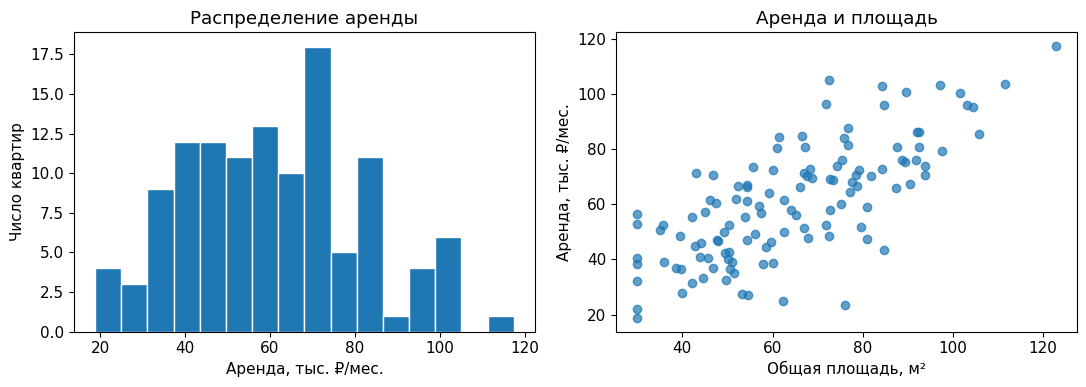

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(data_dev["monthly_rent_thousand_rub"], bins=16, edgecolor="white")
axes[0].set(xlabel="Аренда, тыс. ₽/мес.", ylabel="Число квартир", title="Распределение аренды")
axes[1].scatter(data_dev["total_area_m2"], data_dev["monthly_rent_thousand_rub"], alpha=0.7)
axes[1].set(xlabel="Общая площадь, м²", ylabel="Аренда, тыс. ₽/мес.", title="Аренда и площадь")
plt.tight_layout()
plt.show()

На диаграмме рассеяния видна положительная связь между общей площадью и арендной платой: большие квартиры обычно дороже. Но даже при близкой площади цены заметно различаются. Поэтому одной площади для прогноза недостаточно: в модели понадобятся сведения о расположении, состоянии квартиры и других характеристиках.

In [8]:
corr_cols = [
    "total_area_m2", "living_area_m2", "kitchen_area_m2", "rooms",
    "distance_center_km", "walk_to_metro_min", "renovation_score_1to5",
    "monthly_rent_thousand_rub",
]
corr = data_dev[corr_cols].corr()

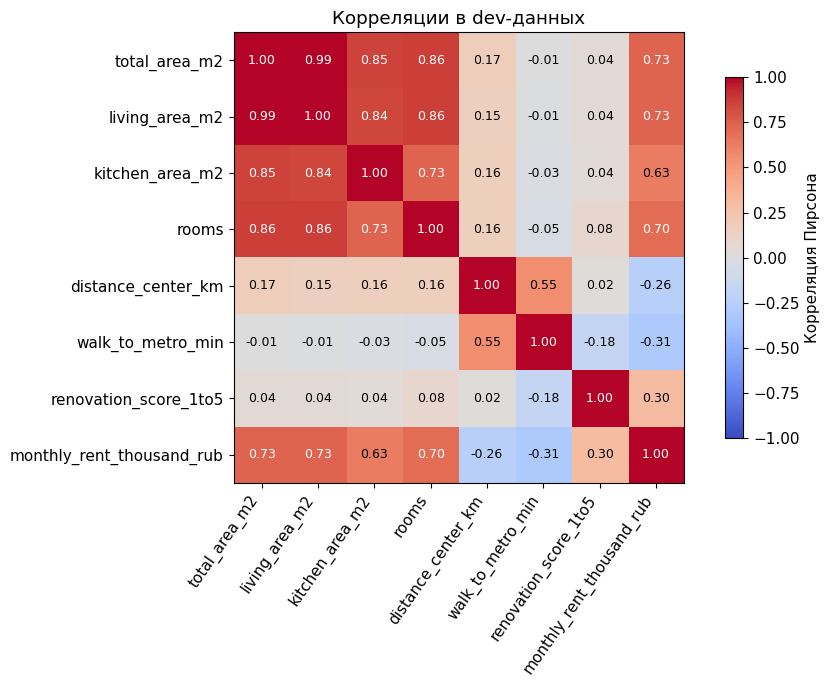

In [9]:
# Тепловая карта сразу показывает направление и силу корреляции.
fig, ax = plt.subplots(figsize=(10, 7))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=55, ha="right")
ax.set_yticks(range(len(corr_cols)), corr_cols)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        value = corr.iloc[i, j]
        color = "white" if abs(value) > 0.65 else "black"
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", color=color, fontsize=9)
fig.colorbar(im, ax=ax, shrink=0.8, label="Корреляция Пирсона")
ax.set_title("Корреляции в dev-данных")
plt.tight_layout()
plt.show()

**Что видно на тепловой карте.** Корреляция общей и жилой площади составляет около **0,994**: два признака почти дублируют друг друга. С арендной платой их корреляции тоже очень близки — **0,731** и **0,734**. Расстояние до центра связано с ценой отрицательно (**−0,257**), а оценка ремонта — положительно (**0,301**). Эти попарные связи помогают познакомиться с данными; далее посмотрим, как модели распределяют коэффициенты между признаками.

## 2. OLS, Ridge и Lasso: коэффициенты и качество

Сначала проведём **одно разбиение dev на train и validation**. Оно позволит наблюдать изменение коэффициентов и одновременно оценивать качество на объектах, которые не использовались для обучения. Позже заменим одну validation-оценку кросс-валидацией.

In [10]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X_dev, y_dev, test_size=0.25, random_state=11
)
print("Train:", len(X_train), "Validation:", len(X_valid))

Train: 90 Validation: 30


### Стандартизация

Для Ridge и Lasso необходимо сделать шкалы признаков сопоставимыми. `StandardScaler` вычисляет среднее и стандартное отклонение каждого столбца **по train**, а затем применяет то же преобразование к validation.

In [11]:
scaler_demo = StandardScaler()
X_train_scaled = scaler_demo.fit_transform(X_train)
X_valid_scaled = scaler_demo.transform(X_valid)

### Обучаем три линейные модели

Начнём с МНК. Затем сравним её с двумя вариантами регуляризации на тех же обучающих объектах.

In [12]:
ols_demo = LinearRegression().fit(X_train_scaled, y_train)

**Ridge** добавляет L2-штраф; `alpha` задаёт его силу. **Lasso** использует L1-штраф и может занулять коэффициенты.

У `Lasso` задаём `max_iter=50000` — максимальное число итераций численного алгоритма, который ищет решение. Это техническое ограничение времени поиска оптимума: 50 000 шагов выполнять не обязательно. Значения `alpha` у Ridge и Lasso нельзя сравнивать напрямую как одинаковую силу штрафа — формы и нормировки целевых функций различаются.

In [13]:
ridge_demo = Ridge(alpha=6).fit(X_train_scaled, y_train)
lasso_demo = Lasso(alpha=0.5, max_iter=50000).fit(X_train_scaled, y_train)

In [14]:
coef_table = pd.DataFrame({
    "OLS": ols_demo.coef_,
    "Ridge": ridge_demo.coef_,
    "Lasso": lasso_demo.coef_,
}, index=X_train.columns)
display(coef_table.round(2))

,OLS,Ridge,Lasso
total_area_m2,0.89,4.41,0.00
living_area_m2,8.75,5.23,9.89
kitchen_area_m2,0.27,0.81,0.00
rooms,7.81,6.82,7.03
distance_center_km,-8.38,-7.56,-7.48
walk_to_metro_min,0.56,-0.12,-0.00
building_age_years,-2.48,-2.20,-1.93
renovation_score_1to5,7.24,6.13,5.72
ceiling_height_m,-1.65,-0.75,-0.00
floor,0.74,0.67,0.24


Посмотрим на две площади в таблице. У МНК коэффициенты общей и жилой площади равны **0,89** и **8,75**. Ridge с `alpha=6` распределила их ровнее: **4,41** и **5,23**. Lasso с `alpha=0.5` занулила коэффициент общей площади, сохранив коэффициент жилой **9,89**. У сильно связанных признаков распределение коэффициентов оказывается чувствительным к способу обучения.

Числа относятся к **стандартизированным признакам**: каждый коэффициент показывает изменение прогноза при увеличении соответствующего признака на одно стандартное отклонение при остальных фиксированных признаках. Сравним, как такие различия отражаются на ошибке на train и validation.

In [15]:
models_demo = {"OLS": ols_demo, "Ridge": ridge_demo, "Lasso": lasso_demo}
comparison_rows = []
for name, model in models_demo.items():
    # Ошибка обучения и ошибка проверки считаются отдельно.
    comparison_rows.append({
        "Модель": name,
        "Train RMSE": root_mean_squared_error(y_train, model.predict(X_train_scaled)),
        "Validation RMSE": root_mean_squared_error(y_valid, model.predict(X_valid_scaled)),
        "Ненулевых коэффициентов": int((np.abs(model.coef_) > 1e-8).sum()),
    })
comparison_demo = pd.DataFrame(comparison_rows)
display(comparison_demo.round(2))

,Модель,Train RMSE,Validation RMSE,Ненулевых коэффициентов
0,OLS,8.76,12.00,12
1,Ridge,8.85,11.54,12
2,Lasso,8.92,11.66,8


На train минимальную RMSE получила МНК — **8,76 тыс. ₽**. У Ridge и Lasso ошибка немного выше: **8,85** и **8,92 тыс. ₽**. Это ожидаемо: МНК непосредственно минимизирует квадратичную ошибку на обучающих данных.

На **validation** порядок другой: МНК — **12,00**, Ridge — **11,54**, Lasso — **11,66 тыс. ₽**. Для этих 30 отложенных квартир обе регуляризованные модели дали меньшую ошибку, чем МНК. Пока это результат одного разбиения; позднее проверим качество на нескольких фолдах.

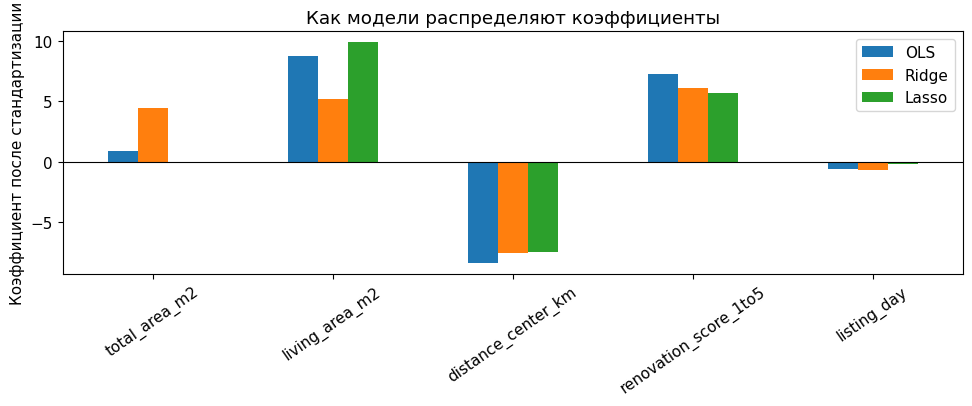

In [16]:
features_to_show = [
    "total_area_m2", "living_area_m2", "distance_center_km",
    "renovation_score_1to5", "listing_day",
]
coef_table.loc[features_to_show].plot.bar(figsize=(10, 4.2), rot=35)
plt.ylabel("Коэффициент после стандартизации")
plt.title("Как модели распределяют коэффициенты")
plt.axhline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

На графике особенно заметно различие между двумя площадями. МНК дала общей площади коэффициент **0,89**, жилой — **8,75**. У Ridge коэффициенты стали ближе друг к другу (**4,41** и **5,23**), а Lasso оставила жилую площадь (**9,89**) и занулила общую.

Коэффициент при дне публикации намного меньше по модулю: **−0,65** у МНК, **−0,69** у Ridge и **−0,17** у Lasso. Этот признак не влияет на цену в нашем генераторе, но на конечной выборке модель всё же может оценить ненулевой коэффициент. Посмотрим, как меняется отбор признаков при усилении L1-штрафа.

### Lasso: сколько признаков остаётся в модели?

Изменим `alpha` и посмотрим, какие коэффициенты становятся точно нулевыми. Для каждого значения обучим Lasso **на том же train** и рассчитаем RMSE на той же validation-части.

In [17]:
lasso_alphas = [0.1, 0.3, 0.5, 1, 1.5, 3, 6, 8]
lasso_rows = []
# Одинаковые train/validation для всех alpha.
for alpha in lasso_alphas:
    model = Lasso(alpha=alpha, max_iter=50000).fit(X_train_scaled, y_train)
    lasso_rows.append({
        "alpha": alpha,
        "Ненулевых": int((np.abs(model.coef_) > 1e-8).sum()),
        "Validation RMSE": root_mean_squared_error(y_valid, model.predict(X_valid_scaled)),
    })
lasso_selection = pd.DataFrame(lasso_rows)
display(lasso_selection.round(3))

,alpha,Ненулевых,Validation RMSE
0,0.1,12,11.828
1,0.3,10,11.715
2,0.5,8,11.660
3,1.0,6,11.527
4,1.5,6,11.515
5,3.0,4,11.839
6,6.0,4,13.221
7,8.0,2,14.282


При `alpha=0.1` Lasso использует все **12 признаков** и получает validation-RMSE **11,83 тыс. ₽**. При `alpha=1.5` остаётся **6 признаков**, а ошибка снижается до **11,52 тыс. ₽**. При `alpha=8` остаются лишь **2 признака**, но RMSE возрастает до **14,28 тыс. ₽**. Сильное сокращение модели уже ухудшает прогнозы на отложенных квартирах.

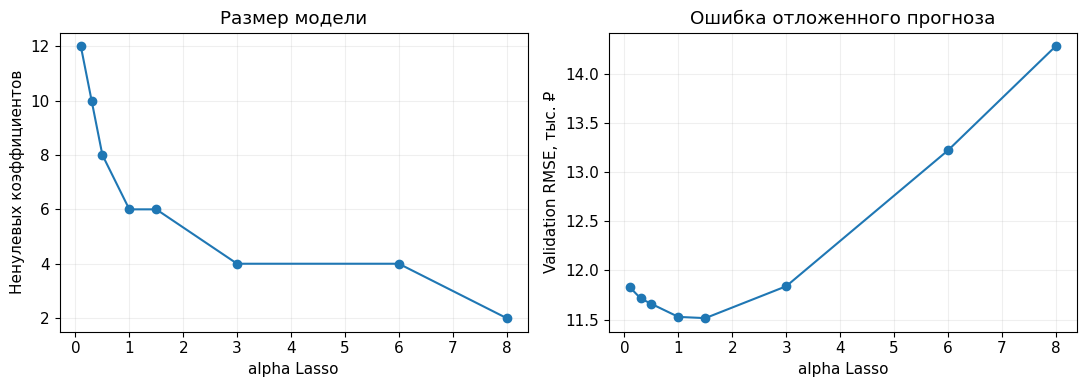

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(lasso_selection["alpha"], lasso_selection["Ненулевых"], "o-")
axes[0].set(xlabel="alpha Lasso", ylabel="Ненулевых коэффициентов", title="Размер модели")
axes[1].plot(lasso_selection["alpha"], lasso_selection["Validation RMSE"], "o-")
axes[1].set(xlabel="alpha Lasso", ylabel="Validation RMSE, тыс. ₽", title="Ошибка отложенного прогноза")
for ax in axes:
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

На левом графике количество ненулевых коэффициентов падает с **12 до 2** по мере усиления штрафа. На правом самая низкая validation-RMSE среди проверенных настроек достигается примерно при **`alpha=1.5`** (**11,52 тыс. ₽**), когда в модели осталось шесть признаков. При дальнейшем усилении штрафа ошибка растёт.

Отбор признаков имеет смысл, когда удаётся упростить модель без заметного ухудшения прогнозов. При этом Lasso оценивает все коэффициенты совместно: из двух похожих признаков может сохранить один и исключить другой.

In [19]:
# Посмотрим, какие признаки исключает Lasso при трёх значениях alpha.
for alpha in [0.5, 1.5, 6]:
    model = Lasso(alpha=alpha, max_iter=50000).fit(X_train_scaled, y_train)
    mask = np.abs(model.coef_) > 1e-8
    excluded = X_train.columns[~mask]
    valid_rmse = root_mean_squared_error(y_valid, model.predict(X_valid_scaled))

    print(f"\nalpha = {alpha:g}: осталось {mask.sum()} из {len(mask)} признаков")
    print("Исключены:")
    for feature in excluded:
        print(f"  - {feature}")
    print(f"Validation RMSE: {valid_rmse:.3f} тыс. ₽")


alpha = 0.5: осталось 8 из 12 признаков
Исключены:
  - total_area_m2
  - kitchen_area_m2
  - walk_to_metro_min
  - ceiling_height_m
Validation RMSE: 11.660 тыс. ₽

alpha = 1.5: осталось 6 из 12 признаков
Исключены:
  - total_area_m2
  - kitchen_area_m2
  - walk_to_metro_min
  - ceiling_height_m
  - floor
  - listing_day
Validation RMSE: 11.515 тыс. ₽

alpha = 6: осталось 4 из 12 признаков
Исключены:
  - total_area_m2
  - kitchen_area_m2
  - walk_to_metro_min
  - building_age_years
  - ceiling_height_m
  - floor
  - balconies
  - listing_day
Validation RMSE: 13.221 тыс. ₽


При `alpha=0.5` Lasso уже исключила общую площадь, но оставила связанную с ней жилую. При `alpha=1.5` дополнительно исключены день публикации и этаж; validation-RMSE составляет **11,52 тыс. ₽**. При `alpha=6` остаются четыре признака, а ошибка возрастает до **13,22 тыс. ₽**.

Таким образом, число исключённых признаков само по себе не определяет качество модели. В нашем примере умеренный L1-штраф позволил использовать меньше переменных при хорошей ошибке на validation.

### Траектории коэффициентов Ridge и Lasso

Построим коэффициенты на последовательности значений `alpha`. Каждая точка траектории соответствует **новому обучению на фиксированном train**.

In [20]:
path_alphas = np.logspace(-2, 2, 22)
path_features = ["total_area_m2", "living_area_m2", "distance_center_km",
                 "renovation_score_1to5", "listing_day"]
paths = {}
for name, model_class in [("Ridge", Ridge), ("Lasso", Lasso)]:
    weights = []
    for alpha in path_alphas:
        options = {"max_iter": 50000} if name == "Lasso" else {}
        model = model_class(alpha=alpha, **options).fit(X_train_scaled, y_train)
        weights.append(model.coef_)
    paths[name] = pd.DataFrame(weights, columns=X_train.columns, index=path_alphas)

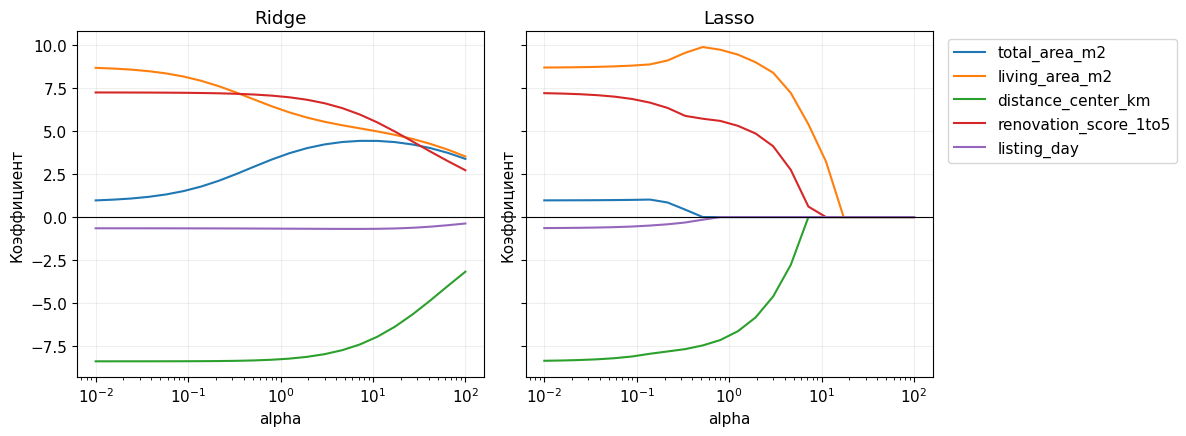

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, name in zip(axes, ["Ridge", "Lasso"]):
    for feature in path_features:
        ax.semilogx(path_alphas, paths[name][feature], label=feature)
    ax.set(title=name, xlabel="alpha", ylabel="Коэффициент")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.grid(alpha=0.2)
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

На графике Ridge коэффициенты при общей и жилой площади постепенно меняются с усилением штрафа, но не достигают точного нуля на показанном диапазоне. У Lasso некоторые линии доходят до нулевой оси и остаются на ней. Например, в предыдущем опыте при `alpha=1.5` модель уже исключала половину признаков.

При интерпретации путей нужно помнить о сильной корреляции площадей: одна из них может взять на себя часть вклада другой. Для выбора силы регуляризации по-прежнему важна ошибка на отложенных объектах.

### Устойчивость коэффициентов при изменении обучающих объектов

Посмотрим, насколько сильнее могут меняться коэффициенты МНК. Создадим 35 бутстрэп-выборок из train: в каждой случайно выберем наблюдения **с возвращением**. На каждой выборке заново обучим МНК и Ridge, включая стандартизацию.

In [22]:
rng = np.random.default_rng(2026)
boot_coefs = []
for repeat in range(35):
    ids = rng.integers(0, len(X_train), len(X_train))
    X_boot = X_train.iloc[ids]
    y_boot = y_train.iloc[ids]
    X_boot_scaled = StandardScaler().fit_transform(X_boot)

    for name, model in [("OLS", LinearRegression()), ("Ridge", Ridge(alpha=6))]:
        model.fit(X_boot_scaled, y_boot)
        boot_coefs.append({"Повтор": repeat, "Модель": name,
                           "Общая площадь": model.coef_[0], "Жилая площадь": model.coef_[1]})
boot_table = pd.DataFrame(boot_coefs)

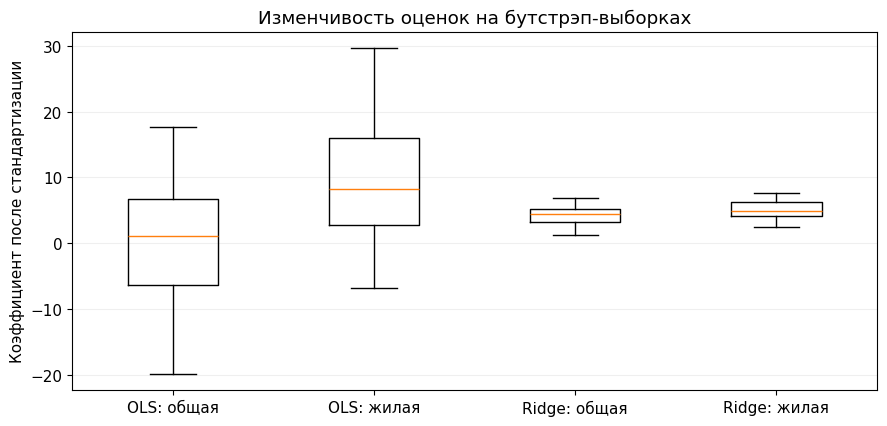

In [23]:
labels = ["OLS: общая", "OLS: жилая", "Ridge: общая", "Ridge: жилая"]
values = [boot_table.loc[boot_table["Модель"] == name, feature].to_numpy()
          for name in ["OLS", "Ridge"]
          for feature in ["Общая площадь", "Жилая площадь"]]
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.boxplot(values, tick_labels=labels)
ax.set(ylabel="Коэффициент после стандартизации", title="Изменчивость оценок на бутстрэп-выборках")
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

На 35 бутстрэп-выборках коэффициенты общей и жилой площади у МНК заметно колеблются: увеличение одного коэффициента нередко сопровождается уменьшением другого. У Ridge коробки для обоих коэффициентов уже, то есть разброс оценок меньше.

Так проявляется одна из полезных сторон L2-регуляризации при почти дублирующихся признаках. Вывод касается **устойчивости коэффициентов**; качество прогнозов мы отдельно измеряем на отложенных данных.

## 3. Кросс-валидация: оцениваем фиксированную модель

Одна validation-оценка зависит от конкретного разбиения. Теперь зафиксируем **Ridge с `alpha=6`** и повторим обучение на пяти вариантах train/validation внутри `dev`. Подбор `alpha` пока не проводим.

`KFold(n_splits=5)` делит 120 объектов на пять непересекающихся фолдов. При `shuffle=True` объекты случайно распределяются по фолдам с фиксированным `random_state`, а затем каждый фолд по очереди служит для проверки.

In [24]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)
fold_indices = list(cv.split(X_dev))
print("Проходов:", len(fold_indices))

Проходов: 5


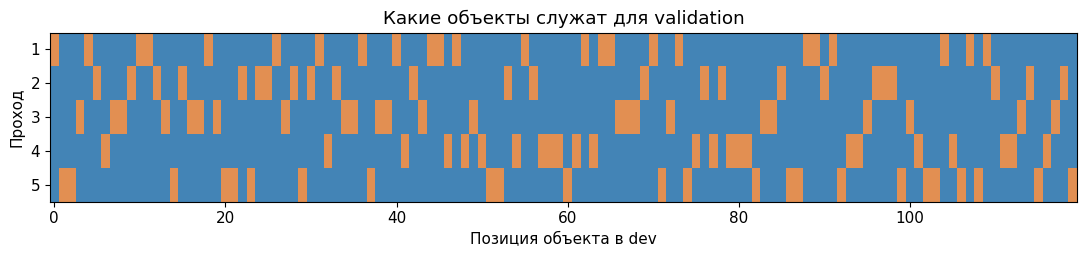

In [25]:
# Голубой — объекты текущего train; оранжевый — validation.
fold_map = np.zeros((5, len(X_dev)))
for fold, (_, valid_idx) in enumerate(fold_indices):
    fold_map[fold, valid_idx] = 1
fig, ax = plt.subplots(figsize=(11, 2.7))
from matplotlib.colors import ListedColormap
ax.imshow(fold_map, aspect="auto", cmap=ListedColormap(["#4384b6", "#e28f52"]), vmin=0, vmax=1)
ax.set(xlabel="Позиция объекта в dev", ylabel="Проход", title="Какие объекты служат для validation")
ax.set_yticks(range(5), range(1, 6))
plt.tight_layout()
plt.show()

При пятифолдовой CV каждый из **120 dev-объектов** один раз попадает в validation. В каждом проходе обучаем модель на **96 объектах** и проверяем на оставшихся **24**. Сначала подробно выполним один проход, затем повторим процедуру для всех пяти фолдов.

In [26]:
train_idx, valid_idx = fold_indices[0]
print("Train:", len(train_idx), "Validation:", len(valid_idx))
print("Первые позиции validation:", valid_idx[:10])

Train: 96 Validation: 24
Первые позиции validation: [ 0  4 10 11 18 26 31 36 40 44]


**Шаг 1.** `split()` возвращает позиции строк. Метод `.iloc` выбирает по ним конкретные объекты и ответы.

In [27]:
X_train_fold = X_dev.iloc[train_idx]
X_valid_fold = X_dev.iloc[valid_idx]
y_train_fold = y_dev.iloc[train_idx]
y_valid_fold = y_dev.iloc[valid_idx]

**Шаг 2.** Стандартизатор обучаем на текущем train. Для validation используем уже найденные средние и стандартные отклонения.

In [28]:
fold_scaler = StandardScaler()
X_train_fold_scaled = fold_scaler.fit_transform(X_train_fold)
X_valid_fold_scaled = fold_scaler.transform(X_valid_fold)

**Шаг 3.** Обучаем новую Ridge с заранее выбранным `alpha=6` и получаем прогнозы для validation.

In [29]:
fold_ridge = Ridge(alpha=6).fit(X_train_fold_scaled, y_train_fold)
y_pred_fold = fold_ridge.predict(X_valid_fold_scaled)

**Шаг 4.** Считаем RMSE по 24 отложенным объектам этого фолда.

In [30]:
first_rmse = root_mean_squared_error(y_valid_fold, y_pred_fold)
print(f"RMSE первого фолда: {first_rmse:.3f} тыс. ₽")

RMSE первого фолда: 10.186 тыс. ₽


### Повторяем пять проходов

Теперь объединим четыре знакомых шага в цикл. При каждой смене фолда заново создаём стандартизатор и обучаем новую модель.

In [31]:
fold_rmse = []
for fold, (train_idx, valid_idx) in enumerate(fold_indices, start=1):
    X_tr, X_va = X_dev.iloc[train_idx], X_dev.iloc[valid_idx]
    y_tr, y_va = y_dev.iloc[train_idx], y_dev.iloc[valid_idx]

    scaler = StandardScaler()  # статистики только текущего train
    X_tr_scaled = scaler.fit_transform(X_tr)
    X_va_scaled = scaler.transform(X_va)
    model = Ridge(alpha=6).fit(X_tr_scaled, y_tr)  # новое обучение
    score = root_mean_squared_error(y_va, model.predict(X_va_scaled))
    fold_rmse.append(score)

In [32]:
fold_scores = pd.DataFrame({"Фолд": range(1, 6), "Validation RMSE": fold_rmse})
display(fold_scores.round(3))
print(f"Средняя CV-RMSE: {np.mean(fold_rmse):.3f} тыс. ₽")
print(f"Корень из средней MSE: {np.sqrt(np.mean(np.square(fold_rmse))):.3f} тыс. ₽")

,Фолд,Validation RMSE
0,1,10.186
1,2,10.090
2,3,9.622
3,4,11.843
4,5,10.045


Средняя CV-RMSE: 10.357 тыс. ₽
Корень из средней MSE: 10.386 тыс. ₽


### Что показала кросс-валидация?

Ранее на одном train/validation-разбиении Ridge с `alpha=6` получила **RMSE 11,54 тыс. ₽**. Теперь та же настройка оценена на пяти фолдах: средняя **CV-RMSE — 10,36 тыс. ₽**. Различаются и обучающие части (90 объектов в первом опыте, 96 в каждом CV-проходе), и проверочные. Поэтому новая цифра означает **другую оценку качества**, а не то, что сама модель стала лучше.

CV позволяет увидеть несколько отложенных ошибок для одной заранее заданной процедуры и меньше зависеть от единственного разбиения. При этом пять оценок получены на пересекающихся обучающих частях, поэтому их не следует считать независимыми экспериментами.

Мы используем **среднюю RMSE по фолдам** — ту же величину, что возвращает `cross_val_score` при `scoring="neg_root_mean_squared_error"` после изменения знака. В предыдущей ячейке дополнительно показан корень из средней MSE: **10,39 тыс. ₽** вместо **10,36 тыс. ₽**. Эти способы агрегации отличаются, поскольку извлечение квадратного корня — нелинейная операция.

Пока с помощью CV мы **оценивали Ridge с фиксированным `alpha=6`**. Далее используем тот же механизм, чтобы выбрать подходящее значение `alpha`.

## 4. Выбираем силу регуляризации Ridge

Теперь задача другая: из нескольких значений `alpha` выбрать то, при котором **средняя validation-RMSE по пяти фолдам минимальна**. Для сопоставимости всех кандидатов используем одни и те же разбиения.

Повторять вручную пять обучений для каждого `alpha` необязательно. `GridSearchCV` сам выполняет перебор и сохраняет результаты всех проверок.

### Зачем нужен `Pipeline`

В ручном цикле мы каждый раз сначала обучали `StandardScaler` на train-фолде, затем Ridge. При автоматической CV эти два действия тоже должны выполняться **заново внутри каждого прохода**. `Pipeline` объединяет преобразование и модель в одну последовательность:

1. `scale`: вычисляет средние и стандартные отклонения текущего train и преобразует признаки;
2. `ridge`: обучает модель на подготовленных признаках.

На validation применяется уже обученная цепочка. Подробно будем изучать составные преобразования позднее; здесь достаточно понимать порядок двух действий.

In [33]:
ridge_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("ridge", Ridge()),
])

Для фиксированной модели такую проверку можно выполнить и без собственного цикла — с помощью `cross_val_score`. Сверим его результаты с ручной CV для Ridge при `alpha=6`. При каждом разбиении стандартизация и обучение выполняются заново.

In [34]:
from sklearn.model_selection import cross_val_score

fixed_ridge_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("ridge", Ridge(alpha=6)),
])
automatic_rmse = -cross_val_score(
    fixed_ridge_pipeline, X_dev, y_dev, cv=cv,
    scoring="neg_root_mean_squared_error",
)
print("Средняя RMSE библиотеки:", round(automatic_rmse.mean(), 3))
print("Совпадают ли ошибки по фолдам:", np.allclose(automatic_rmse, fold_rmse))

Средняя RMSE библиотеки: 10.357
Совпадают ли ошибки по фолдам: True


Получили те же пять ошибок, что в ручном цикле, и то же среднее — **10,36 тыс. ₽**. Теперь мы знаем, как оценить Ridge с одним заранее заданным `alpha`. Следующий шаг — сравнить несколько настроек по одинаковым фолдам. Эту задачу автоматизирует `GridSearchCV`.

### Как устроен `GridSearchCV`

`GridSearchCV` получает **модель**, **сетку параметров**, **способ CV** и **метрику**. Для каждой настройки он создаёт новые модели, оценивает их на одинаковых фолдах и сравнивает среднее качество.

Мы явно перечислим возможные значения `alpha`: от очень слабого до сильного L2-штрафа. Это учебная сетка; её диапазон зависит от шкалы и структуры конкретных данных.

In [35]:
ridge_alphas = [0.01, 0.1, 0.3, 1, 3, 6, 10, 30, 100, 300]
ridge_grid = {"ridge__alpha": ridge_alphas}

В ключе `ridge__alpha` двойное подчёркивание отделяет имя шага `ridge` от его параметра `alpha`.

- `estimator` — вся цепочка `scale → ridge`.
- `param_grid` — значения параметров для проверки.
- `cv` — тот же `KFold` на пяти фолдах.
- `scoring="neg_root_mean_squared_error"` — **отрицательная RMSE**: у sklearn больший score считается лучшим, поэтому ошибке меняют знак.
- `return_train_score=True` — дополнительно сохранить ошибки на обучающих частях.

По умолчанию `refit=True`: после выбора лучшей настройки `GridSearchCV` заново обучает цепочку на всех переданных `dev`-данных.

In [36]:
ridge_cv = KFold(n_splits=5, shuffle=True, random_state=42)
ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=ridge_grid,
    cv=ridge_cv,
    scoring="neg_root_mean_squared_error",
    return_train_score=True,
)

Запускаем поиск. При 10 значениях `alpha` и пяти фолдах будет **50 обучений для оценивания**, а после выбора выполнится ещё одно обучение итоговой цепочки на всех `dev`.

In [37]:
ridge_search.fit(X_dev, y_dev)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...e', Ridge())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'ridge__alpha': [0.01, 0.1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : 

### Читаем результат поиска

`best_params_` содержит параметры выбранной настройки; `best_score_` — **средний score её validation-фолдов**. Поскольку он отрицателен, для получения обычной RMSE меняем знак. `cv_results_` хранит результаты всех проверенных кандидатов.

In [38]:
print("Выбранный alpha:", ridge_search.best_params_["ridge__alpha"])
print("best_score_ (отрицательная RMSE):", round(ridge_search.best_score_, 3))
print("CV-RMSE выбранной Ridge:", round(-ridge_search.best_score_, 3), "тыс. ₽")

Выбранный alpha: 10
best_score_ (отрицательная RMSE): -10.336
CV-RMSE выбранной Ridge: 10.336 тыс. ₽


In [39]:
ridge_raw = pd.DataFrame(ridge_search.cv_results_)
ridge_summary = pd.DataFrame({
    "alpha": ridge_raw["param_ridge__alpha"].astype(float),
    "Train RMSE": -ridge_raw["mean_train_score"],
    "CV-RMSE": -ridge_raw["mean_test_score"],
})
display(ridge_summary.round(3))

,alpha,Train RMSE,CV-RMSE
0,0.01,9.196,10.649
1,0.10,9.197,10.618
2,0.30,9.202,10.574
3,1.00,9.215,10.502
4,3.00,9.240,10.416
5,6.00,9.281,10.357
6,10.00,9.352,10.336
7,30.00,9.792,10.557
8,100.00,11.281,11.842
9,300.00,14.079,14.463


`mean_train_score` получен по обучающим частям, `mean_test_score` — по validation-фолдам (в терминологии API sklearn они обозначены `test`, но это **внутренние validation-части CV**, а не наш финальный `X_test`). На графике покажем обе средние RMSE с положительным знаком.

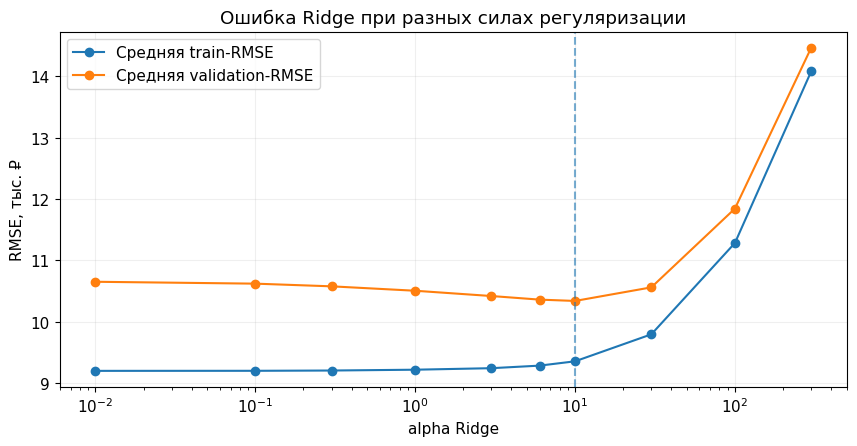

In [40]:
fig, ax = plt.subplots(figsize=(8.7, 4.6))
ax.semilogx(ridge_summary["alpha"], ridge_summary["Train RMSE"], "o-", label="Средняя train-RMSE")
ax.semilogx(ridge_summary["alpha"], ridge_summary["CV-RMSE"], "o-", label="Средняя validation-RMSE")
ax.axvline(ridge_search.best_params_["ridge__alpha"], linestyle="--", alpha=0.6)
ax.set(xlabel="alpha Ridge", ylabel="RMSE, тыс. ₽", title="Ошибка Ridge при разных силах регуляризации")
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
plt.show()

На нашей сетке минимальная средняя CV-RMSE — **10,34 тыс. ₽** при **`alpha=10`**. При почти нулевом штрафе (`alpha=0.01`) ошибка выше — **10,65 тыс. ₽**. При слишком сильном (`alpha=300`) она увеличивается до **14,46 тыс. ₽**.

Ошибка на обучающих частях при увеличении `alpha` растёт примерно с **9,20** до **14,08 тыс. ₽**. По этой кривой следовало бы выбрать самую слабую регуляризацию. Но по отложенным фолдам лучший вариант находится внутри сетки. Поэтому силу штрафа выбираем по **validation**, а не по train.

## 5. Elastic Net: два гиперпараметра

Elastic Net сочетает L1- и L2-штрафы. Теперь будем выбирать **два параметра одновременно**: `alpha` задаёт общую силу регуляризации, а `l1_ratio` — долю L1-компоненты. В отличие от Ridge, каждая конфигурация определяется парой чисел.

In [41]:
enet_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("enet", ElasticNet(max_iter=50000)),
])

In [42]:
enet_alphas = [0.03, 0.1, 0.3, 1, 3, 10]
enet_ratios = [0.2, 0.5, 0.8, 1.0]
enet_grid = {
    "enet__alpha": enet_alphas,
    "enet__l1_ratio": enet_ratios,
}
print("Конфигураций:", len(enet_alphas) * len(enet_ratios))

Конфигураций: 24


Получили 6 × 4 = **24 комбинации**. Каждую проверяем на пяти одинаковых фолдах: 120 CV-обучений, затем автоматическое переобучение лучшей конфигурации на всех `dev`.

In [43]:
enet_cv = KFold(n_splits=5, shuffle=True, random_state=42)
enet_search = GridSearchCV(
    estimator=enet_pipeline,
    param_grid=enet_grid,
    cv=enet_cv,
    scoring="neg_root_mean_squared_error",
)

In [44]:
enet_search.fit(X_dev, y_dev)  # 24 комбинации, по пять фолдов
print("Лучшая пара:", enet_search.best_params_)
print("CV-RMSE:", round(-enet_search.best_score_, 3), "тыс. ₽")

Лучшая пара: {'enet__alpha': 0.3, 'enet__l1_ratio': 0.8}
CV-RMSE: 10.339 тыс. ₽


В `best_params_` теперь находятся сразу два числа. Значения подбирались совместно: изменение `l1_ratio` может изменить то, какое `alpha` оказывается наиболее удачным.

Преобразуем `cv_results_` в удобную таблицу.

In [45]:
enet_raw = pd.DataFrame(enet_search.cv_results_)
enet_results = pd.DataFrame({
    "alpha": enet_raw["param_enet__alpha"].astype(float),
    "l1_ratio": enet_raw["param_enet__l1_ratio"].astype(float),
    "CV-RMSE": -enet_raw["mean_test_score"],
})
display(enet_results.sort_values("CV-RMSE").head(8).round(3))

,alpha,l1_ratio,CV-RMSE
10,0.30,0.8,10.339
4,0.10,0.2,10.342
9,0.30,0.5,10.358
5,0.10,0.5,10.369
6,0.10,0.8,10.420
11,0.30,1.0,10.434
0,0.03,0.2,10.436
8,0.30,0.2,10.458


### Тепловая карта двумерной сетки

Столбец — значение `alpha`, строка — `l1_ratio`. Число в ячейке — **средняя RMSE по пяти validation-фолдам** данной комбинации. Меньше — лучше.

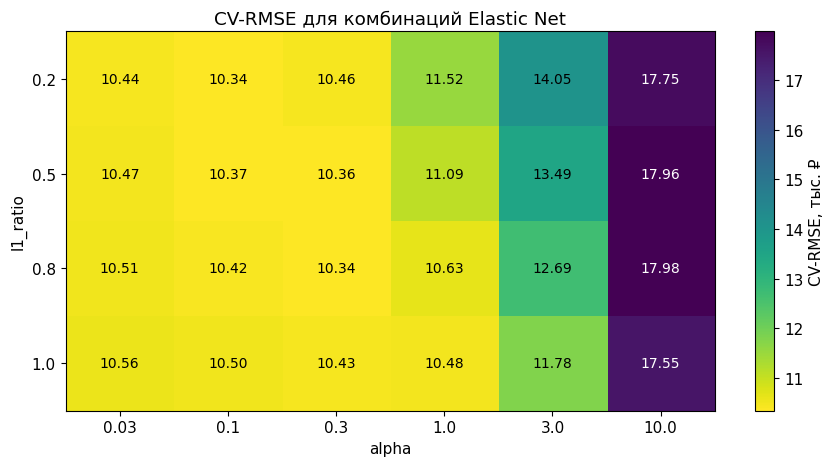

In [46]:
heatmap = enet_results.pivot(index="l1_ratio", columns="alpha", values="CV-RMSE")
fig, ax = plt.subplots(figsize=(9, 4.8))
im = ax.imshow(heatmap.to_numpy(), aspect="auto", cmap="viridis_r")
ax.set_xticks(range(len(heatmap.columns)), [str(x) for x in heatmap.columns])
ax.set_yticks(range(len(heatmap.index)), [str(x) for x in heatmap.index])
for i in range(heatmap.shape[0]):
    for j in range(heatmap.shape[1]):
        value = heatmap.iloc[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=10,
                color="white" if im.norm(value) > 0.55 else "black")
ax.set(xlabel="alpha", ylabel="l1_ratio", title="CV-RMSE для комбинаций Elastic Net")
fig.colorbar(im, ax=ax, label="CV-RMSE, тыс. ₽")
plt.tight_layout()
plt.show()

На тепловой карте лучший результат — **CV-RMSE 10,339 тыс. ₽** при **`alpha=0.3`, `l1_ratio=0.8`**. Почти такую же ошибку (**10,342 тыс. ₽**) дала комбинация **`alpha=0.1`, `l1_ratio=0.2`**. Две достаточно разные смеси L1 и L2 оказались близки по качеству.

Более сильный штраф в правой части карты заметно увеличивает ошибку. На этих данных подбор двух гиперпараметров дал несколько практически равных по CV-качеству вариантов.

## 6. Сравнение настроенных моделей и финальный test

Мы выполнили **две отдельные настройки гиперпараметров**: нашли лучшее `alpha` внутри Ridge и лучшую пару (`alpha`, `l1_ratio`) внутри Elastic Net. Теперь сравним уже настроенные процедуры по **одинаковой CV-метрике и одинаковым фолдам**. Оба поиска оценивали весь процесс — стандартизацию вместе с регрессией.

In [47]:
comparison = pd.DataFrame([
    {"Модель": "Ridge", "CV-RMSE": -ridge_search.best_score_},
    {"Модель": "Elastic Net", "CV-RMSE": -enet_search.best_score_},
])
display(comparison.round(4))

,Модель,CV-RMSE
0,Ridge,10.3359
1,Elastic Net,10.3393


Для Ridge лучшая CV-RMSE равна **10,3359 тыс. ₽**, для Elastic Net — **10,3393 тыс. ₽**. Разница составляет около **0,0034 тыс. ₽**, то есть примерно **3,4 рубля в месяц** в единицах целевой переменной. По такой малой разнице не стоит делать вывод о существенном превосходстве одной процедуры.

В этом эксперименте для наглядности используем формальное правило: выбираем меньшую среднюю CV-RMSE. Поэтому ниже будет выбрана Ridge. В прикладной задаче также могут иметь значение разреженность и устойчивость коэффициентов.

In [48]:
# score отрицателен: большее значение соответствует меньшей RMSE.
if ridge_search.best_score_ > enet_search.best_score_:
    selected_search = ridge_search
    selected_name = "Ridge"
else:
    selected_search = enet_search
    selected_name = "Elastic Net"
print("Выбрана модель:", selected_name)

Выбрана модель: Ridge


### Что делает автоматическое `refit`

По умолчанию `GridSearchCV` после CV обучает **ещё одну модель на всех dev-объектах**, используя выбранные гиперпараметры. Она доступна как `best_estimator_`. Это вся цепочка, включая стандартизатор.

In [49]:
final_model = selected_search.best_estimator_
print("Готовая цепочка:", final_model)

Готовая цепочка: Pipeline(steps=[('scale', StandardScaler()), ('ridge', Ridge(alpha=10))])


Для наглядности вручную повторим такое же окончательное обучение **на примере Ridge**: сначала создадим цепочку с выбранным `alpha`, затем обучим её на всех dev. Это демонстрация механики `refit`; для итогового тестирования ниже используется выбранная модель `final_model`.

In [50]:
manual_ridge = Pipeline([
    ("scale", StandardScaler()),
    ("ridge", Ridge(alpha=ridge_search.best_params_["ridge__alpha"])),
])
manual_ridge.fit(X_dev, y_dev)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('scale', ...), ('ridge', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"alpha alpha: {float, ndarray of shape (n_targets,)}, default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.",10
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None


In [51]:
# Проверяем, что ручное итоговое обучение Ridge совпало с refit GridSearchCV.
refit_predictions = ridge_search.best_estimator_.predict(X_dev)
manual_predictions = manual_ridge.predict(X_dev)
print("Наибольшее различие прогнозов:", np.max(np.abs(refit_predictions - manual_predictions)))

Наибольшее различие прогнозов: 0.0


### Независимая проверка

До этого момента мы не использовали 40 отложенных квартир. Теперь применяем к ним уже выбранную и обученную цепочку **один раз**. Сравнивать Ridge и Elastic Net по test и затем выбирать победителя было бы некорректно: выбор подстроился бы под test.

In [52]:
final_pred = final_model.predict(X_test)
test_rmse = root_mean_squared_error(y_test, final_pred)
print("Независимая test-RMSE:", round(test_rmse, 3), "тыс. ₽")

Независимая test-RMSE: 12.471 тыс. ₽


В результате поиска выбрана Ridge с `alpha=10`. После автоматического переобучения на всех **120 dev-квартирах** она дала на независимом test **RMSE 12,47 тыс. ₽**. Это выше CV-оценки (**10,34 тыс. ₽**): итоговая проверочная выборка оказалась сложнее для данной модели. На этом основной регрессионный эксперимент завершён.

## 7. Регуляризация логистической регрессии

Регуляризация применяется и в классификации. Кратко проверим её на реальном наборе *Breast Cancer Wisconsin (Diagnostic)*: 569 наблюдений и 30 числовых признаков. Будем прогнозировать бинарную метку с помощью логистической регрессии и выбирать силу L2-штрафа с помощью CV.

In [53]:
cancer = load_breast_cancer(as_frame=True)
X_clf = cancer.data
y_clf = cancer.target
print("Размер:", X_clf.shape)
print("Метки:", dict(enumerate(cancer.target_names)))
print("Доли классов:")
display(y_clf.value_counts(normalize=True).sort_index().round(3))

Размер: (569, 30)
Метки: {0: np.str_('malignant'), 1: np.str_('benign')}
Доли классов:


target
0    0.373
1    0.627
Name: proportion, dtype: float64

Все признаки числовые. В sklearn класс **0 соответствует malignant**, а **1 — benign**; при вычислении ROC AUC положительным считается именно класс 1. Это учебная задача знакомства с API, а не инструмент клинического принятия решений.

Для логистической регрессии sklearn использует параметр **`C`**, обратно пропорциональный силе регуляризации: меньший `C` означает более сильный штраф. Значение по умолчанию — **`C=1.0`**, поэтому регуляризация включена уже в стандартной конфигурации. При увеличении `C` штраф ослабевает; в современных версиях sklearn `C=np.inf` соответствует отсутствию штрафа. Обозначение пришло из традиции регуляризованных линейных классификаторов, где `C` задаёт вес ошибок относительно штрафа. Из-за различий в нормировках равенство `C=1/λ` из нашей лекционной формулы буквально применять нельзя.

In [54]:
Xc_dev, Xc_test, yc_dev, yc_test = train_test_split(
    X_clf, y_clf, test_size=0.25, random_state=42, stratify=y_clf
)
clf_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

`StratifiedKFold` сохраняет примерно одинаковые доли классов в фолдах. При `shuffle=True` объекты **каждого класса случайно распределяются по фолдам при построении разбиения**; затем используются пять зафиксированных наборов индексов. Новое случайное перемешивание перед каждым проходом не выполняется.

In [55]:
clf_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("logreg", LogisticRegression(max_iter=5000)),
])
clf_grid = {"logreg__C": [0.001, 0.01, 0.1, 1, 10, 100]}

В отличие от регрессии, здесь будем **максимизировать ROC AUC**. Более высокая ROC AUC означает лучшее ранжирование положительных объектов по предсказанной вероятности.

In [56]:
clf_search = GridSearchCV(
    estimator=clf_pipeline,
    param_grid=clf_grid,
    cv=clf_cv,
    scoring="roc_auc",
)
clf_search.fit(Xc_dev, yc_dev)  # подбираем C по среднему ROC AUC

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._iter=5000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'logreg__C': [0.001, 0.01, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displ

In [57]:
clf_results = pd.DataFrame(clf_search.cv_results_)
clf_summary = pd.DataFrame({
    "C": clf_results["param_logreg__C"].astype(float),
    "CV ROC AUC": clf_results["mean_test_score"],
})
display(clf_summary.round(4))
print("Выбранный C:", clf_search.best_params_["logreg__C"])

,C,CV ROC AUC
0,0.001,0.9863
1,0.010,0.9926
2,0.100,0.9953
3,1.000,0.9962
4,10.000,0.9901
5,100.000,0.9877


Выбранный C: 1


На наших данных средняя ROC AUC по CV выросла с **0,9863** при `C=0.001` до **0,9962** при `C=1`, а при `C=100` снизилась до **0,9877**. Следовательно, ослабление регуляризации помогало только до некоторого значения `C`. `GridSearchCV` выбрал **`C=1`**.

In [58]:
clf_probs = clf_search.best_estimator_.predict_proba(Xc_test)[:, 1]
print("Test ROC AUC:", round(roc_auc_score(yc_test, clf_probs), 4))

Test ROC AUC: 0.9977


И в регрессии, и в классификации мы использовали одну организацию эксперимента: выбор настройки внутри `dev` и отдельную итоговую оценку на test. Различались модели, гиперпараметры и метрики.

## 8. Самостоятельная работа

Выполните два небольших исследования по уже рассчитанным результатам. Данные для финального test повторно не используем.

**Задание 1. Почти одинаковое качество — одинаковая модель?** Найдите три лучшие конфигурации Elastic Net. Для каждой обучите Elastic Net на всех `dev` (стандартизацию включите в `Pipeline`) и посчитайте количество ненулевых коэффициентов. Сравните разреженность моделей и их CV-RMSE. Сделайте короткий вывод.

In [59]:
# Напишите код: три лучшие комбинации и количество ненулевых коэффициентов

**Задание 2. Зависит ли выбор `alpha` от разбиения?** Повторите поиск Ridge с тем же набором `ridge_alphas`, но используйте `KFold(n_splits=5, shuffle=True, random_state=21)`. Сравните выбранное `alpha` и CV-RMSE с первоначальным поиском. В объяснении опирайтесь на то, что состав фолдов изменился.

In [60]:
# Напишите код: новый KFold, GridSearchCV и сравнение с первым поиском

## Итоги

Ridge меняет величину и устойчивость коэффициентов, Lasso умеет занулять их, Elastic Net объединяет L1- и L2-штрафы. На отложенной выборке можно оценить изменение качества при разных силах регуляризации.

K-fold повторяет обучение и проверку на нескольких разбиениях. `GridSearchCV` использует эту же процедуру, чтобы сравнить настройки и автоматически обучить итоговую модель. После всех решений остаётся отдельная независимая проверка на test.